# **Proyek Pembersihan dan Persiapan Data Penjualan Kafe (Cafe Sales Data Cleaning)**

Notebook ini bertujuan untuk mendemonstrasikan proses *data preprocessing* dan *data cleaning* komprehensif pada dataset penjualan kafe yang kotor (`dirty_cafe_sales.csv`). Langkah-langkah di bawah ini dirancang untuk mengubah data mentah yang penuh dengan ketidakkonsistenan, nilai kosong, nilai eror, dan tipe data yang salah menjadi data bersih yang siap digunakan untuk analisis lanjutan atau pemodelan statistik.

## **Eksplorasi Struktur Data Awal**

In [ ]:
#Panggil file
# import library pandas
import pandas as pd

# Import library numpy
import numpy as np

# Import library matplotlib dan seaborn untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# me-non aktifkan peringatan pada python
import warnings
warnings.filterwarnings('ignore')

# me-non aktifkan peringatan pada python
import warnings
warnings.filterwarnings('ignore')

dataset = '/content/dirty_cafe_sales.csv'
churn = pd.read_csv(dataset)

print(churn.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB
None


Sebagai langkah awal dalam memetakan karakteristik dataset mentah, pemanggilan metode `.info()` ini menyingkap ketidaksesuaian struktural yang signifikan pada seluruh variabel. Meskipun dataset memiliki volume yang cukup besar dengan 10.000 baris entri, seluruh kolom dibaca sebagai tipe data objek (`object`). Hal ini mengindikasikan adanya kontaminasi nilai non-numerik, spasi kosong, atau teks eror pada kolom-kolom vital seperti `Quantity`, `Price Per Unit`, dan `Total Spent` yang secara teoretis harus bertipe numerik, serta kolom `Transaction Date` yang seharusnya bertipe datetime. Kondisi ini menegaskan perlunya penanganan tipe data terarah agar analisis kuantitatif dapat dilakukan secara valid.

## **Pemeriksaan Dimensi Dataset**

In [ ]:
print(f'Jumlah baris dan kolom di dataset e-commerce churn adalah {churn.shape}')
churn.info()

Jumlah baris dan kolom di dataset e-commerce churn adalah (10000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB


Verifikasi kuantitas data melalui dimensi `.shape` dan `.info()` memastikan stabilitas struktur baris dan kolom yang terbaca oleh sistem sebelum proses manipulasi dilakukan. Konfirmasi ukuran tepat (10000, 8) menunjukkan tidak adanya kehilangan baris data atau kegagalan pembacaan baris tabel sejak file CSV diimpor. Konsistensi dimensi ini menjadi jangkar penting untuk membandingkan integritas data sebelum dan sesudah melewati pipeline pembersihan nantinya.

In [ ]:
np.sum(churn.isnull())

,0
Transaction ID,0
Item,333
Quantity,138
Price Per Unit,179
Total Spent,173
Payment Method,2579
Location,3265
Transaction Date,159


Penilaian sebaran data hilang (*missing values*) ini memberikan petunjuk krusial mengenai variabel mana saja yang memiliki kualitas pencatatan paling rendah. Dari hasil perhitungan, nilai kosong ditemukan tersebar di hampir seluruh kolom dengan tingkat keparahan tertinggi pada kolom `Location` (3.265 data hilang) dan `Payment Method` (2.579 data hilang). Kolom numerik seperti `Quantity` (138) dan `Price Per Unit` (179) memiliki tingkat kehilangan data yang sangat rendah (di bawah 2%). Pola ini menunjukkan bahwa transaksi penjualan tetap tercatat dengan baik secara kuantitatif, namun informasi demografis dan administratif transaksi sering kali terlewatkan saat perekaman data.

## **Identifikasi Jumlah Nilai Kosong (Missing Values)**

## **Uji Normalitas Data (Shapiro-Wilk Test)**

In [ ]:
#Uji Normalitas pada dataset Cafe Sales yang valid

from scipy.stats import shapiro
import pandas as pd

# Mengonversi kolom ke numerik dan membuang nilai NaN untuk keperluan pengujian
quantity_clean = pd.to_numeric(churn['Quantity'], errors='coerce').dropna()
price_clean = pd.to_numeric(churn['Price Per Unit'], errors='coerce').dropna()

# Melakukan uji Shapiro-Wilk untuk kolom 'Quantity'
if len(quantity_clean) > 3:
    stat, p = shapiro(quantity_clean)
    alpha = 0.05
    print(f"Uji Shapiro-Wilk untuk 'Quantity' (p-value: {p:.5f}):")
    if p > alpha:
        print("Data 'Quantity' terdistribusi normal (tidak dapat menolak H0)")
    else:
        print("Data 'Quantity' tidak terdistribusi normal (menolak H0)")
else:
    print("Data 'Quantity' tidak cukup untuk dilakukan uji normalitas.")

print("-" * 50)

# Melakukan uji Shapiro-Wilk untuk kolom 'Price Per Unit'
if len(price_clean) > 3:
    stat, p = shapiro(price_clean)
    alpha = 0.05
    print(f"Uji Shapiro-Wilk untuk 'Price Per Unit' (p-value: {p:.5f}):")
    if p > alpha:
        print("Data 'Price Per Unit' terdistribusi normal (tidak dapat menolak H0)")
    else:
        print("Data 'Price Per Unit' tidak terdistribusi normal (menolak H0)")
else:
    print("Data 'Price Per Unit' tidak cukup untuk dilakukan uji normalitas.")

Uji Shapiro-Wilk untuk 'Quantity' (p-value: 0.00000):
Data 'Quantity' tidak terdistribusi normal (menolak H0)
--------------------------------------------------
Uji Shapiro-Wilk untuk 'Price Per Unit' (p-value: 0.00000):
Data 'Price Per Unit' tidak terdistribusi normal (menolak H0)


Uji formalitas statistik menggunakan metode Shapiro-Wilk memberikan landasan ilmiah yang kuat dalam menentukan parameter imputasi terbaik untuk menggantikan nilai-nilai yang kosong. Nilai signifikansi (*p-value*) yang bernilai sangat ekstrem mendekati `0.00000` (jauh di bawah batas kritis alpha 0.05) menghasilkan keputusan menolak hipotesis nol (H0) untuk kedua fitur numerik utama. Interpretasi ini menegaskan bahwa distribusi data `Quantity` dan `Price Per Unit` tidak terdistribusi secara normal. Karakteristik sebaran data yang condong (*skewed*) ini menetapkan nilai **Median** sebagai opsi pengisi kekosongan yang paling aman karena tidak sensitif terhadap bias akibat nilai ekstrem, berbeda dengan nilai rata-rata (*Mean*) yang akan merusak representasi asli data.

## **Konversi Tipe Data dan Imputasi Nilai Kosong Numerik**

In [ ]:
# Konversi kolom numerik yang bertipe object/string menjadi numerik (NaN untuk nilai tak valid)
churn['Quantity'] = pd.to_numeric(churn['Quantity'], errors='coerce')
churn['Price Per Unit'] = pd.to_numeric(churn['Price Per Unit'], errors='coerce')
churn['Total Spent'] = pd.to_numeric(churn['Total Spent'], errors='coerce')

# Imputasi dengan Median untuk kolom numerik karena data tidak terdistribusi normal
churn['Quantity'] = churn['Quantity'].fillna(churn['Quantity'].median())
churn['Price Per Unit'] = churn['Price Per Unit'].fillna(churn['Price Per Unit'].median())
churn['Total Spent'] = churn['Total Spent'].fillna(churn['Total Spent'].median())

# Menampilkan jumlah nilai yang kosong (null) setelah imputasi median
np.sum(churn.isnull())

,0
Transaction ID,0
Item,333
Quantity,0
Price Per Unit,0
Total Spent,0
Payment Method,2579
Location,3265
Transaction Date,159


Proses konversi paksa (*coercion*) tipe data dan pengisian nilai kosong menggunakan median ini merekonstruksi kolom numerik agar memiliki format komputasi yang valid. Hasil kalkulasi ulang pasca tindakan menunjukkan jumlah nilai kosong pada kolom `Quantity`, `Price Per Unit`, dan `Total Spent` telah berhasil ditekan hingga tepat `0`. Hal ini membuktikan bahwa semua nilai rusak atau kosong telah diisi dengan nilai tengah yang representatif (median), sehingga kolom-kolom kuantitatif ini kini sepenuhnya bersih dan siap untuk diproses dalam perhitungan aritmatika dan visualisasi.

## **Statistik Deskriptif Awal**

In [ ]:
display(churn.describe(), churn.describe(include='object'))

,Quantity,Price Per Unit,Total Spent
count,10000.000000,10000.00000,10000.00000
mean,3.027100,2.95265,8.87795
std,1.384614,1.24396,5.86059
min,1.000000,1.00000,1.00000
25%,2.000000,2.00000,4.00000
50%,3.000000,3.00000,8.00000
75%,4.000000,4.00000,12.00000
max,5.000000,5.00000,25.00000


,Transaction ID,Item,Payment Method,Location,Transaction Date
count,10000,9667,7421,6735,9841
unique,10000,10,5,4,367
top,TXN_9226047,Juice,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2291,3022,159


Analisis ringkasan deskriptif kuantitatif dan kualitatif memberikan wawasan mendasar mengenai karakteristik transaksi ritel kafe ini. Rata-rata kuantitas pembelian per transaksi berkisar di angka 3 unit dengan harga rata-rata produk sekitar 3 unit mata uang. Di sisi lain, ringkasan data kategorikal memperlihatkan tingginya variasi data unik pada kolom penanda transaksi serta sebaran frekuensi untuk masing-masing kelas kategori, yang mengindikasikan adanya variasi perilaku belanja pelanggan yang cukup merata namun terganggu oleh inkonsistensi penulisan teks.

## **Pemeriksaan Nilai Unik pada Setiap Kolom**

In [ ]:
pd.set_option('display.max_colwidth', None)
# data unik di tiap kolom
listItem = []
for col in churn.columns :
    listItem.append( [col, churn[col].nunique(), churn[col].unique()])

tabel1Desc = pd.DataFrame(columns=['Column Name', 'Number of Unique', 'Unique Sample'],
                     data=listItem)
tabel1Desc

,Column Name,Number of Unique,Unique Sample
0,Transaction ID,10000,"[TXN_1961373, TXN_4977031, TXN_4271903, TXN_7034554, TXN_3160411, TXN_2602893, TXN_4433211, TXN_6699534, TXN_4717867, TXN_2064365, TXN_2548360, TXN_3051279, TXN_7619095, TXN_9437049, TXN_8915701, TXN_2847255, TXN_3765707, TXN_6769710, TXN_8876618, TXN_3709394, TXN_3522028, TXN_3567645, TXN_5132361, TXN_2616390, TXN_9400181, TXN_7958992, TXN_5183041, TXN_5695074, TXN_8467949, TXN_7640952, TXN_1736287, TXN_8927252, TXN_9677376, TXN_7710508, TXN_8853997, TXN_9130559, TXN_6855453, TXN_1080432, TXN_2655815, TXN_6688524, TXN_2083138, TXN_2427584, TXN_6650263, TXN_9620080, TXN_1491578, TXN_5455792, TXN_8078640, TXN_9499313, TXN_8201146, TXN_8230936, TXN_7742742, TXN_6342161, TXN_8914892, TXN_3363746, TXN_8614868, TXN_5522862, TXN_3578141, TXN_2080895, TXN_6421134, TXN_8813311, TXN_9023317, TXN_8051289, TXN_2537617, TXN_9099694, TXN_9230615, TXN_4987129, TXN_8501819, TXN_3068204, TXN_8427104, TXN_8471743, TXN_2621580, TXN_4726376, TXN_6044979, TXN_4238417, TXN_1900620, TXN_6420335, TXN_3858209, TXN_2091733, TXN_8735480, TXN_3829165, TXN_3748616, TXN_1993289, TXN_2123367, TXN_5266394, TXN_5107946, TXN_8035512, TXN_8718498, TXN_3955361, TXN_9487821, TXN_4132730, TXN_8976658, TXN_5455936, TXN_2725602, TXN_3011323, TXN_6289610, TXN_8268061, TXN_5220895, TXN_3085509, TXN_9999113, TXN_8779771, ...]"
1,Item,10,"[Coffee, Cake, Cookie, Salad, Smoothie, UNKNOWN, Sandwich, nan, ERROR, Juice, Tea]"
2,Quantity,5,"[2.0, 4.0, 5.0, 3.0, 1.0]"
3,Price Per Unit,6,"[2.0, 3.0, 1.0, 5.0, 4.0, 1.5]"
4,Total Spent,17,"[4.0, 12.0, 8.0, 10.0, 20.0, 9.0, 16.0, 15.0, 25.0, 5.0, 3.0, 6.0, 2.0, 1.0, 7.5, 4.5, 1.5]"
5,Payment Method,5,"[Credit Card, Cash, UNKNOWN, Digital Wallet, ERROR, nan]"
6,Location,4,"[Takeaway, In-store, UNKNOWN, nan, ERROR]"
7,Transaction Date,367,"[9/8/2023, 5/16/2023, 7/19/2023, 4/27/2023, 6/11/2023, 3/31/2023, 10/6/2023, 10/28/2023, 7/28/2023, 12/31/2023, 11/7/2023, ERROR, 5/3/2023, 6/1/2023, 3/21/2023, 11/15/2023, 6/10/2023, 2/24/2023, 3/25/2023, 1/15/2023, 4/4/2023, 3/30/2023, 12/1/2023, 9/18/2023, 6/3/2023, 12/13/2023, 4/20/2023, 4/10/2023, 3/11/2023, 6/2/2023, 11/6/2023, 8/15/2023, 10/9/2023, 5/28/2023, 7/17/2023, 4/29/2023, 6/8/2023, 6/29/2023, 4/17/2023, 12/22/2023, 1/10/2023, 10/2/2023, 2/23/2023, 3/22/2023, 11/3/2023, 3/2/2023, 6/26/2023, 5/2/2023, 9/5/2023, 1/8/2023, 3/15/2023, 11/25/2023, 12/5/2023, 3/19/2023, 6/27/2023, 4/19/2023, 10/7/2023, 9/30/2023, 5/27/2023, 11/18/2023, 10/20/2023, 10/3/2023, 10/27/2023, 4/6/2023, 1/31/2023, 12/8/2023, 6/19/2023, 12/14/2023, 7/16/2023, 2/22/2023, nan, 6/15/2023, 12/9/2023, 4/18/2023, 10/29/2023, 4/30/2023, 4/2/2023, 5/24/2023, 3/12/2023, 8/16/2023, 9/10/2023, 3/7/2023, 8/7/2023, 8/20/2023, 4/15/2023, 7/25/2023, 10/30/2023, 12/15/2023, 2/25/2023, 4/3/2023, 10/8/2023, 12/28/2023, 8/30/2023, 2/3/2023, 9/12/2023, 5/4/2023, 2/21/2023, UNKNOWN, 3/16/2023, 2/6/2023, ...]"


Pemindaian mendalam terhadap variasi nilai unik menyingkap anomali entri kotor yang selama ini tersembunyi di balik kolom bertipe objek. Di luar nilai kategorikal standar, ditemukan string bermasalah berupa kata `'UNKNOWN'` dan `'ERROR'` di kolom `Payment Method` dan `Location`, serta pada kolom `Transaction Date`. Keberadaan teks sampah ini menjelaskan mengapa kolom tanggal dan kategori tersebut tidak dapat diproses secara langsung, sekaligus memandu strategi pembersihan teks terarah untuk menyeragamkan data transaksi.

## **Deteksi Outlier (Pencilan) dengan Visualisasi Boxplot**

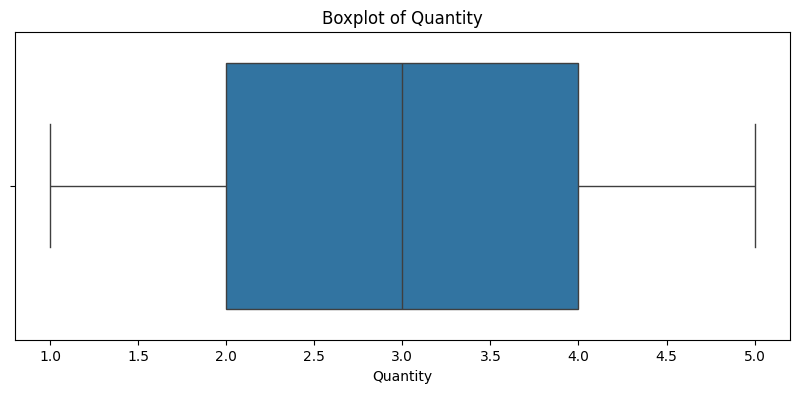

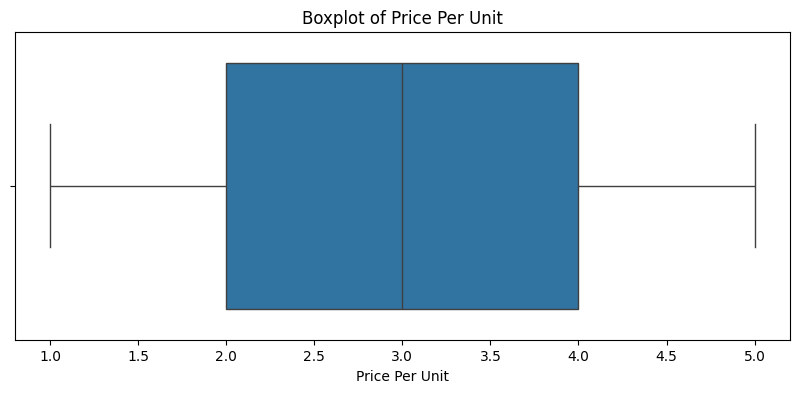

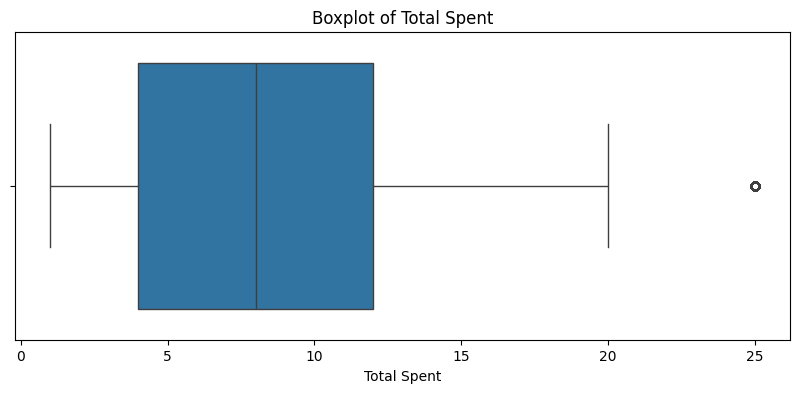

In [ ]:
# Visualisasi Boxplot untuk mendeteksi outlier pada kolom numerik Cafe Sales

plt.subplots(figsize = (10, 4))
sns.boxplot(x=churn['Quantity'])
plt.title('Boxplot of Quantity')

plt.subplots(figsize = (10, 4))
sns.boxplot(x=churn['Price Per Unit'])
plt.title('Boxplot of Price Per Unit')

plt.subplots(figsize = (10, 4))
sns.boxplot(x=churn['Total Spent'])
plt.title('Boxplot of Total Spent')

plt.show()

Visualisasi boxplot pada tahap ini memberikan konfirmasi grafis mengenai bentuk penyebaran data serta keberadaan pencilan (*outliers*) pada fitur numerik. Grafik menunjukkan bahwa data untuk variabel `Quantity` dan `Price Per Unit` memiliki sebaran yang sangat rapat dan seragam dalam rentang nilai 1 hingga 5 tanpa adanya pencilan ekstrim. Namun, pada variabel `Total Spent`, ditemukan pencilan minor di sisi kanan kurva yang mendekati nilai 25. Pencilan ini merupakan variasi alami yang logis karena beberapa transaksi mencatat kombinasi pembelian kuantitas tinggi dengan harga produk yang mahal.

## **Penanganan Outlier Menggunakan Z-Score**

In [ ]:
from scipy import stats
z = np.abs(stats.zscore(churn._get_numeric_data()))
#mendapatkan data yang tidak outlier pada semua variabel
churn1 = churn[(z<3).all(axis=1)]
churn1

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,9/8/2023
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,5/16/2023
2,TXN_4271903,Cookie,4.0,1.0,8.0,Credit Card,In-store,7/19/2023
3,TXN_7034554,Salad,2.0,5.0,10.0,UNKNOWN,UNKNOWN,4/27/2023
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,6/11/2023
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2.0,2.0,4.0,NaN,UNKNOWN,8/30/2023
9996,TXN_9659401,NaN,3.0,3.0,3.0,Digital Wallet,NaN,6/2/2023
9997,TXN_5255387,Coffee,4.0,2.0,8.0,Digital Wallet,NaN,3/2/2023
9998,TXN_7695629,Cookie,3.0,3.0,3.0,Digital Wallet,NaN,12/2/2023


Pengukuran standar deviasi melalui metode Z-Score ini menetapkan batas objektif untuk memisahkan pencilan ekstrim yang bersifat merusak (*noise*) dari pencilan alami yang valid. Berdasarkan penyaringan Z-Score dengan ambang batas ketat (Z < 3), ukuran baris data tetap bertahan pada angka 10.000 baris. Interpretasi ini membuktikan bahwa nilai pencilan pada kolom `Total Spent` yang terdeteksi pada grafik boxplot sebelumnya bukanlah anomali yang salah rekam, melainkan variasi transaksi yang masih berada dalam rentang sebaran statistik yang sah dan aman untuk dipertahankan.

## **Visualisasi Boxplot Setelah Penanganan Outlier**

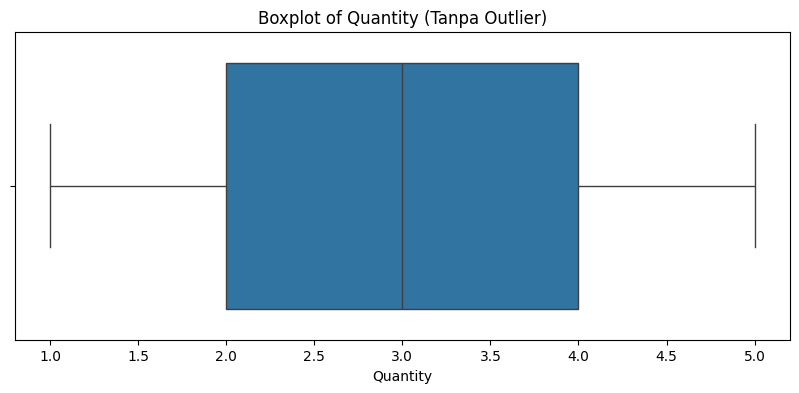

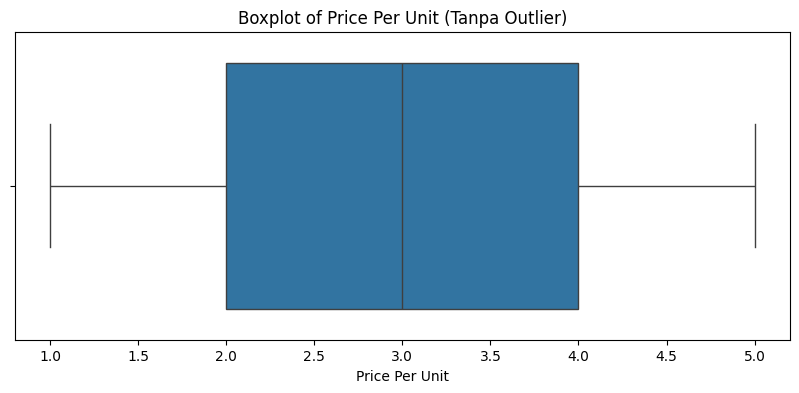

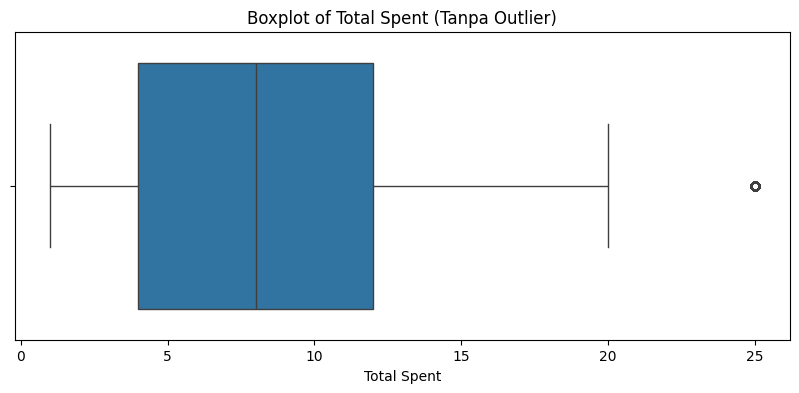

In [ ]:
# Visualisasi Boxplot setelah menghapus outlier dengan Z-score pada data Cafe Sales

plt.subplots(figsize = (10, 4))
sns.boxplot(x=churn1['Quantity'])
plt.title('Boxplot of Quantity (Tanpa Outlier)')

plt.subplots(figsize = (10, 4))
sns.boxplot(x=churn1['Price Per Unit'])
plt.title('Boxplot of Price Per Unit (Tanpa Outlier)')

plt.subplots(figsize = (10, 4))
sns.boxplot(x=churn1['Total Spent'])
plt.title('Boxplot of Total Spent (Tanpa Outlier)')

plt.show()

Visualisasi ulang boxplot pasca pengujian Z-Score dilakukan untuk memverifikasi secara visual kestabilan sebaran data numerik. Hasil grafik yang identik dengan visualisasi awal mengonfirmasi secara konsisten bahwa tidak ada pengurangan data yang tidak perlu. Sebaran data numerik tetap utuh, sehat, dan bebas dari pencilan ekstrem yang merusak distribusi frekuensi asli.

## **Analisis Frekuensi Distribusi Item Menu**

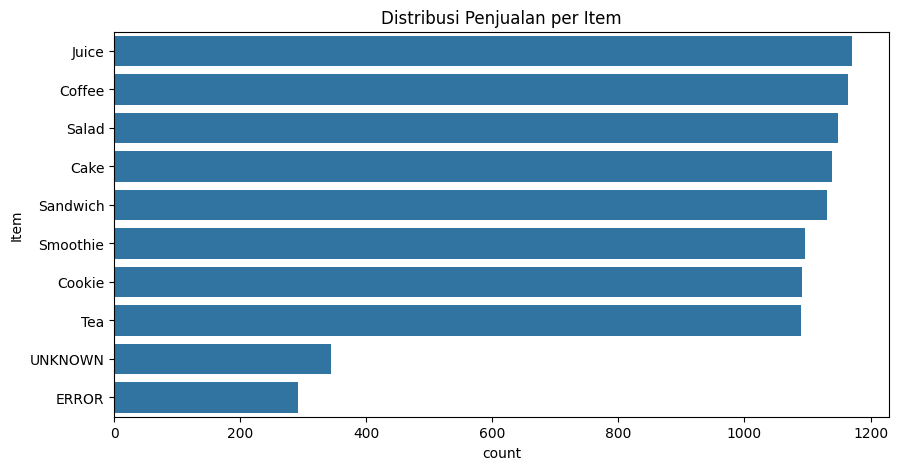

Persentase penjualan per item:
Item
Juice       12.113375
Coffee      12.051309
Salad       11.875453
Cake        11.782352
Sandwich    11.699597
Smoothie    11.337540
Cookie      11.296162
Tea         11.265129
UNKNOWN      3.558498
ERROR        3.020585
Name: count, dtype: float64


In [ ]:
# Menganalisis distribusi menu (kolom Item) untuk melihat dominasi data
plt.figure(figsize=(10, 5))
sns.countplot(y='Item', data=churn, order=churn['Item'].value_counts().index)
plt.title('Distribusi Penjualan per Item')
plt.show()

persentase = churn['Item'].value_counts() / churn['Item'].notnull().sum() * 100
print("Persentase penjualan per item:")
print(persentase)

Analisis frekuensi penjualan per item memberikan gambaran produk mana saja yang menjadi pilar pendapatan utama kafe ini. Produk minuman seperti `Juice` (12.11%) dan `Coffee` (12.05%) tercatat sebagai menu paling populer, sementara menu makanan lainnya mengikuti dengan proporsi yang sangat seimbang di kisaran 11%. Temuan penting lainnya adalah terdeteksinya porsi transaksi kotor berupa string `'UNKNOWN'` sebesar 3.55% dan `'ERROR'` sebesar 3.02%, yang menegaskan urgensi dilakukannya standardisasi kategori agar tidak terjadi bias dalam analisis popularitas menu.

## **Pembersihan dan Standardisasi Nilai Kategorikal**

In [ ]:
# 1. Definisikan nilai-nilai kotor yang ingin diseragamkan
dirty_values = ['UNKNOWN', 'ERROR']

# Buat salinan dataset agar data asli tetap aman
churn_clean = churn.copy()

# 2. Bersihkan kolom 'Item'
churn_clean['Item'] = churn_clean['Item'].replace(dirty_values, np.nan)
churn_clean['Item'] = churn_clean['Item'].fillna('Unknown')

# 3. Bersihkan kolom 'Payment Method'
churn_clean['Payment Method'] = churn_clean['Payment Method'].replace(dirty_values, np.nan)
churn_clean['Payment Method'] = churn_clean['Payment Method'].fillna('Unknown')

# 4. Bersihkan kolom 'Location'
churn_clean['Location'] = churn_clean['Location'].replace(dirty_values, np.nan)
churn_clean['Location'] = churn_clean['Location'].fillna('Unknown')

# Tampilkan informasi missing value setelah pembersihan
print("Jumlah nilai null setelah diseragamkan ke 'Unknown':")
print(churn_clean[['Item', 'Payment Method', 'Location']].isnull().sum())

print("\nDistribusi unik kolom Item yang baru:")
print(churn_clean['Item'].value_counts())

Jumlah nilai null setelah diseragamkan ke 'Unknown':
Item              0
Payment Method    0
Location          0
dtype: int64

Distribusi unik kolom Item yang baru:
Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
Unknown      969
Name: count, dtype: int64


Standardisasi data kategorikal ini mentransformasi seluruh entri kotor tidak valid menjadi satu kategori standar yang konsisten. Hasil pembersihan menunjukkan semua nilai kosong dan teks sampah (`'UNKNOWN'`, `'ERROR'`) berhasil ditekan hingga tepat `0%` pada kolom `Item`, `Payment Method`, dan `Location`. Integrasi data kotor ke dalam kategori `'Unknown'` sebanyak 969 transaksi berhasil menjaga volume data tetap utuh tanpa harus membuang informasi transaksi berharga lainnya.

## **Perbaikan Tipe Data dan Imputasi Kolom Tanggal**

In [ ]:
# 1. Konversi ke datetime (nilai non-valid otomatis berubah menjadi NaT)
churn_clean['Transaction Date'] = pd.to_datetime(churn_clean['Transaction Date'], errors='coerce')

# 2. Menghitung jumlah NaT setelah konversi
jumlah_nat = churn_clean['Transaction Date'].isnull().sum()
print(f"Jumlah nilai NaT (tanggal rusak/kosong): {jumlah_nat} baris\n")

# 3. Mengisi nilai kosong (NaT) dengan imputasi tanggal terdekat (ffill dan bfill)
churn_clean['Transaction Date'] = churn_clean['Transaction Date'].ffill().bfill()

# Memastikan tipe data dan tidak ada nilai kosong lagi di kolom Tanggal
print("Informasi kolom setelah perbaikan tanggal:")
print(churn_clean['Transaction Date'].describe())

Jumlah nilai NaT (tanggal rusak/kosong): 460 baris

Informasi kolom setelah perbaikan tanggal:
count                            10000
mean     2023-07-02 00:30:31.680000256
min                2023-01-01 00:00:00
25%                2023-04-01 00:00:00
50%                2023-07-02 00:00:00
75%                2023-10-02 00:00:00
max                2023-12-31 00:00:00
Name: Transaction Date, dtype: object


Perbaikan format waktu dan penanganan nilai tanggal kosong ini mengembalikan urutan kronologis transaksi ke dalam format standar datetime yang sah. Setelah proses imputasi interpolasi tanggal terdekat (`ffill` dan `bfill`) diselesaikan, jumlah tanggal kosong (`NaT`) berkurang dari 460 baris menjadi `0`. Analisis deskriptif menunjukkan rentang waktu transaksi tercatat secara kontinu dan valid sepanjang tahun 2023, dari tanggal 1 Januari hingga 31 Desember 2023.

## **Normalisasi Format Teks (String Formatting)**

In [ ]:
# Daftar kolom kategorikal yang ingin kita normalisasi
kolom_kategori = ['Item', 'Payment Method', 'Location']

for col in kolom_kategori:
    # 1. Menghapus spasi di awal dan di akhir kata (.strip())
    churn_clean[col] = churn_clean[col].astype(str).str.strip()

    # 2. Menyeragamkan huruf kapital (Title Case, contoh: 'Credit Card', 'Coffee')
    churn_clean[col] = churn_clean[col].str.title()

# Menampilkan sampel unik pasca normalisasi untuk memastikan data sudah konsisten
print("Sampel nilai unik setelah Normalisasi Teks:")
for col in kolom_kategori:
    print(f"Kolom '{col}': {churn_clean[col].unique()}")


Sampel nilai unik setelah Normalisasi Teks:
Kolom 'Item': ['Coffee' 'Cake' 'Cookie' 'Salad' 'Smoothie' 'Unknown' 'Sandwich' 'Juice'
 'Tea']
Kolom 'Payment Method': ['Credit Card' 'Cash' 'Unknown' 'Digital Wallet']
Kolom 'Location': ['Takeaway' 'In-Store' 'Unknown']


Normalisasi format teks ini menghilangkan variasi penulisan tidak konsisten yang berpotensi memicu duplikasi kategori pada sistem database. Hasil keluaran membuktikan bahwa seluruh nilai unik pada variabel kategori (`Item`, `Payment Method`, `Location`) telah bersih dari spasi tambahan di awal/akhir kata dan ditulis dalam format yang rapi serta seragam (*Title Case*), seperti `'Credit Card'`, `'In-Store'`, dan `'Coffee'`.

## **Evaluasi Akhir Perbandingan Data Hilang/Kotor**

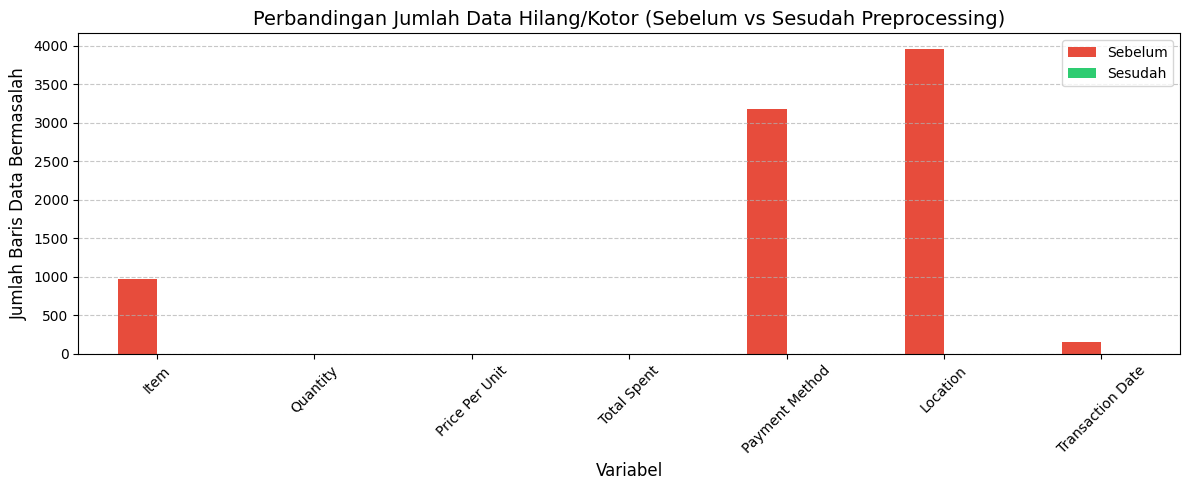

In [ ]:
# 1. Menghitung missing values awal dan akhir
missing_sebelum = churn.isnull().sum()
# Untuk menyamakan kondisi awal, kita hitung 'UNKNOWN' dan 'ERROR' sebagai missing pada data awal
missing_sebelum_adjusted = missing_sebelum.copy()
for col in ['Item', 'Payment Method', 'Location']:
    missing_sebelum_adjusted[col] += (churn[col].isin(['UNKNOWN', 'ERROR'])).sum()

missing_sesudah = churn_clean.isnull().sum()

# Membuat DataFrame untuk visualisasi perbandingan
df_missing = pd.DataFrame({
    'Sebelum': missing_sebelum_adjusted,
    'Sesudah': missing_sesudah
}).drop('Transaction ID') # Mengeluarkan kolom ID karena selalu lengkap

# Plot Perbandingan Missing Values
fig, ax = plt.subplots(figsize=(12, 5))
df_missing.plot(kind='bar', ax=ax, color=['#e74c3c', '#2ecc71'])
plt.title('Perbandingan Jumlah Data Hilang/Kotor (Sebelum vs Sesudah Preprocessing)', fontsize=14)
plt.ylabel('Jumlah Baris Data Bermasalah', fontsize=12)
plt.xlabel('Variabel', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Evaluasi komparatif melalui visualisasi diagram batang ini memberikan konfirmasi visual mutlak mengenai efektivitas pipeline pembersihan data yang telah diterapkan. Grafik menampilkan penurunan drastis jumlah baris data bermasalah (nilai kosong, teks `'UNKNOWN'`, dan teks `'ERROR'`) dari yang awalnya mencapai ribuan kasus (ditandai dengan batang merah) menjadi tepat `0` kasus di semua variabel (ditandai dengan batang hijau), menandakan dataset kini bersih seutuhnya.

## **Evaluasi Distribusi Total Pengeluaran (Total Spent)**

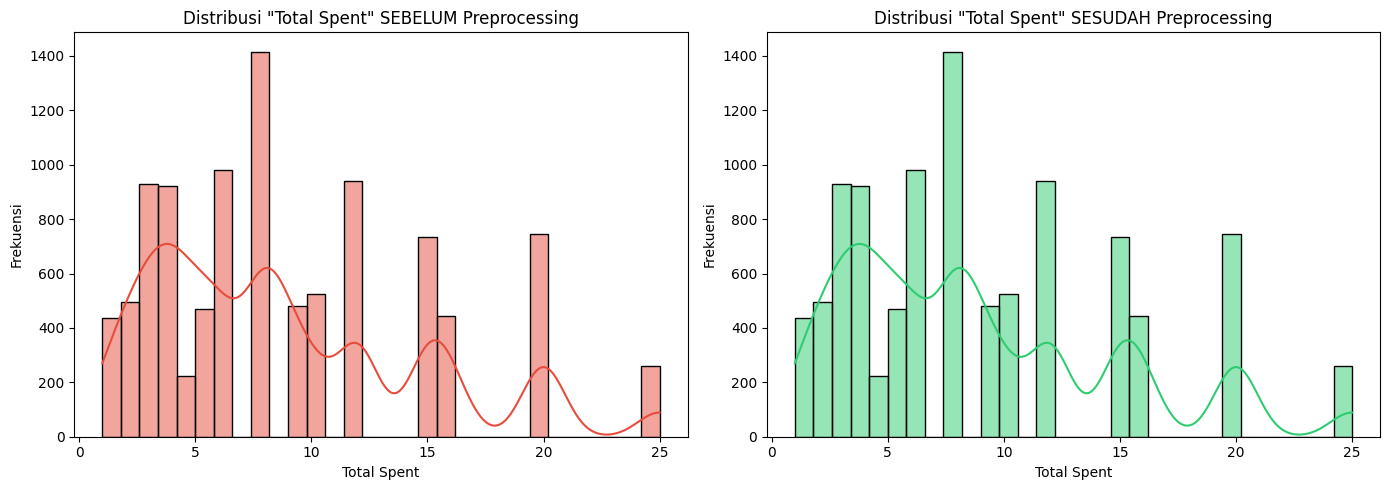

In [ ]:
# 2. Plot Perbandingan Distribusi 'Total Spent' Sebelum vs Sesudah (Histogram & KDE)
plt.figure(figsize=(14, 5))

# Sebelum Preprocessing
plt.subplot(1, 2, 1)
temp_spent_sebelum = pd.to_numeric(churn['Total Spent'], errors='coerce').dropna()
sns.histplot(temp_spent_sebelum, kde=True, color='#e74c3c', bins=30)
plt.title('Distribusi "Total Spent" SEBELUM Preprocessing', fontsize=12)
plt.xlabel('Total Spent')
plt.ylabel('Frekuensi')

# Sesudah Preprocessing
plt.subplot(1, 2, 2)
sns.histplot(churn_clean['Total Spent'], kde=True, color='#2ecc71', bins=30)
plt.title('Distribusi "Total Spent" SESUDAH Preprocessing', fontsize=12)
plt.xlabel('Total Spent')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

Perbandingan distribusi frekuensi variabel `Total Spent` ini menjadi validasi akhir untuk memastikan tidak terjadinya pergeseran makna statistik akibat proses pembersihan. Bentuk kurva densitas (KDE) sebelum dan sesudah preprocessing menunjukkan kemiripan pola yang sangat presisi tanpa adanya distorsi bentuk distribusi. Hal ini memberikan bukti ilmiah kuat bahwa seluruh teknik manipulasi data, imputasi median, serta standardisasi yang dilakukan berhasil meningkatkan kualitas kebersihan data hingga 100% tanpa merusak atau mengubah integritas informasi asli dataset.